# Cyera: offline project walkthrough

Inspect synthetic Activity Events and the team’s saved experimental results. This notebook makes no network calls, trains no models, and needs no API keys. It does not validate the live pipeline. Run from the repository root or a subdirectory using Python 3; only the standard library and the notebook display runtime are used.

In [1]:
from pathlib import Path
import csv, json
from collections import Counter
from IPython.display import SVG, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "CONTEXT.md").exists())
def read_json(relative):
    return json.loads((ROOT / relative).read_text())
with (ROOT / "data/synthetic_enterprise_activity/v1/activity.csv").open() as f:
    activity = list(csv.DictReader(f))
print("Synthetic activity events:", len(activity))
print("Columns:", ", ".join(activity[0]))
print("Events by department:", dict(sorted(Counter(row["department"] for row in activity).items())))


Synthetic activity events: 265
Columns: event_id, timestamp, employee_id, department, job_role, application_name, domain, event_type, usage_purpose, data_sensitivity_tier
Events by department: {'Engineering': 102, 'Finance': 33, 'IT': 7, 'Marketing': 17, 'Operations': 6, 'Product': 3, 'Research': 5, 'Sales': 62, 'Support': 30}


## Data boundary

All activity is fictional. Vendor policy facts in scenario metadata are synthetic assumptions, not real vendor claims. Activity counts illustrate scenario coverage, not enterprise prevalence. Files under `evaluation_only/` must never become inference or retrieval inputs.

In [2]:
ai = read_json("notebooks/ai_cascade/test2_jev_results.json")
print("Evaluation pages:", ai["pages"], "Gold labels:", ai["gold_determinations"])
for key in ("keyword_rule", "cascade_v2", "jev_cascade"):
    row = ai[key]
    print(f"{key}: resolved macro-F1={row['resolved_macro_f1']:.3f}; accuracy={row['resolved_accuracy']:.3f}; false alarms={row['false_alarms']}; misses={row['missed_ai']}; abstained={row['resolved_abstained']}")


Evaluation pages: 409 Gold labels: {'ai': 226, 'unresolved': 68, 'non_ai': 115}
keyword_rule: resolved macro-F1=0.889; accuracy=0.906; false alarms=27; misses=5; abstained=0
cascade_v2: resolved macro-F1=0.929; accuracy=0.909; false alarms=6; misses=17; abstained=19
jev_cascade: resolved macro-F1=0.931; accuracy=0.918; false alarms=7; misses=14; abstained=15


## Category accuracy and abstention

All-answer accuracy and accuracy among retained answers have different denominators. Report coverage alongside selective accuracy. These are saved team experiments, not a new evaluation.

In [3]:
category = read_json("notebooks/category_classification/test_results.json")
for method, sets in category["results"].items():
    row = sets["test_pages[full]"]
    selective = row["frozen_threshold"]
    print(method, "homepage rows:", row["rows"], "accuracy:", round(row["accuracy"], 3), "coverage:", round(selective["coverage"], 3), "accuracy when answering:", selective["accuracy_when_answering"])


knn[bge-small-en-v1.5,k=15] homepage rows: 89 accuracy: 0.528 coverage: 0.551 accuracy when answering: 0.6326530612244898
tfidf_lr[C=4,plain] homepage rows: 89 accuracy: 0.472 coverage: 0.596 accuracy when answering: 0.6037735849056604
embed_lr[bge-small-en-v1.5,C=10,plain] homepage rows: 89 accuracy: 0.427 coverage: 0.236 accuracy when answering: 0.7619047619047619
jev homepage rows: 89 accuracy: 0.494 coverage: 0.0 accuracy when answering: None


<IPython.core.display.SVG object>


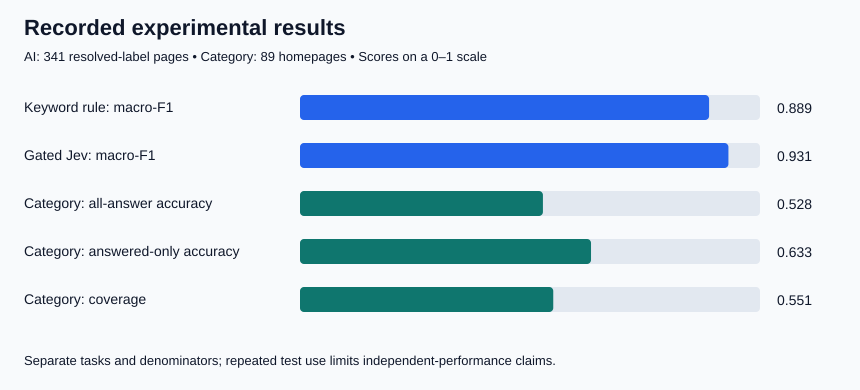

In [4]:
display(SVG(filename=str(ROOT / "docs/figures/recorded-results.svg")))

## Interpretation and next experiments

The gated Jev configuration reduced false alarms relative to the keyword rule, with more misses and abstentions. Category transfer to homepages remains difficult: the neighbor vote answers about 55% of test homepages at about 63% accuracy. Test2 and the Category test split were reused in earlier comparisons; AI reference labels came from two passes of the same model family. Fresh independent test data and human review are needed for new performance claims.

For setup, baseline training commands, API usage, and verification boundaries, see [the project guide](../docs/project-guide.md).